# 12 - Ajuste de Coeficientes NASA-7 a partir de Datos Tabulados de Cp(T)

La base de datos empaquetada se construyó convirtiendo el `thermo.inp` FORTRAN de
la NASA a SQLite. A veces tiene sus **propios** datos de $C_p(T)$ (mediciones, DFT,
otra correlación) y quiere expresarlos en la forma NASA-7 usada en esta colección.
`pyglenn` 0.3.0 añadió `fit_nasa7` y `fit_nasa7_multi` para eso.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from pyglenn import (
    ThermochemicalCalculator, fit_nasa7, fit_nasa7_multi,
    ThermoDBQuery, R_GLENN, R,
)

print("R       (CODATA 2018)          =", R)
print("R_GLENN (CODATA 1986, NASA set) =", R_GLENN)


R       (CODATA 2018)          = 8.31446261815324
R_GLENN (CODATA 1986, NASA set) = 8.31451


## 1. Un conjunto de datos tabulados de Cp(T)

Como ejemplo reproducible tomamos el polinomio de O₂ del propio `pyglenn`, lo
muestreamos en una malla y tratamos esas muestras como datos "medidos" a reajustar.


In [2]:
with ThermochemicalCalculator() as calc:
    o2 = calc.get_available_species("O2", exact_match=True)[0].id
    T = np.linspace(300, 1000, 40)
    cp_true = np.array([calc.calculate_properties(o2, t).cp for t in T])

print(f"{len(T)} tabulated points from 300 to 1000 K")
print("Cp(300)  =", cp_true[0], "J/(mol.K)")
print("Cp(1000) =", cp_true[-1], "J/(mol.K)")


40 tabulated points from 300 to 1000 K
Cp(300)  = 29.387511058506735 J/(mol.K)
Cp(1000) = 34.8825450091414 J/(mol.K)


## 2. Ajuste de un solo intervalo (`fit_nasa7`)

`fit_nasa7(temperatures, cp_values)` ajusta los siete coeficientes de capacidad
calorífica $a_1 \ldots a_7$ por mínimos cuadrados. La constante de entalpía $b_1$
**no** se ajusta — se deriva para que la convención NASA-7
$H^\circ(t_\mathrm{ref}) = h_\mathrm{ref}$ se cumpla exactamente.


In [3]:
coeffs = fit_nasa7(T, cp_true)
print("Fitted NASA-7 coefficients:")
print(coeffs)

# Evaluate the fit and compare against the tabulated data
cp_fit = np.array([ThermoDBQuery.calculate_cp(coeffs, t) * R_GLENN for t in T])
err = np.max(np.abs(cp_fit - cp_true))
print(f"\nmax |Cp_fit - Cp_true| = {err:.2e} J/(mol.K)")

# Enthalpy anchor: H(298.15) = 0 by the NASA-7 convention
h_ref = ThermoDBQuery.calculate_h(coeffs, 298.15) * R_GLENN * 298.15
print(f"H(298.15 K) from the fit = {h_ref:.2f} J/mol  (anchored to 0)")


Fitted NASA-7 coefficients:
NASACoefficients(a1=-34255.63420000793, a2=484.70009700009837, a3=1.1190109609995529, a4=0.004293889240001003, a5=-6.836300520011998e-07, a6=-2.0233726999992616e-09, a7=1.0390400179998217e-12, b1=-3391.454868460136, b2=0.0)

max |Cp_fit - Cp_true| = 6.39e-14 J/(mol.K)
H(298.15 K) from the fit = 0.00 J/mol  (anchored to 0)


## 3. Ajuste multi-intervalo (`fit_nasa7_multi`)

Rangos de temperatura amplios están mal condicionados para un solo polinomio. La NASA
divide cada especie en intervalos; `fit_nasa7_multi` hace lo mismo, imponiendo
**continuidad de $C_p$ y de su primera derivada** en cada punto de quiebre.


In [4]:
breakpoints = [600.0]
coeffs_multi = fit_nasa7_multi(T, cp_true, breakpoints)
print(f"{len(coeffs_multi)} intervals with breakpoint at {breakpoints[0]} K")

def eval_multi(coeffs, breakpoints, t):
    idx = 0 if t <= breakpoints[0] else 1
    return ThermoDBQuery.calculate_cp(coeffs[idx], t) * R_GLENN

cp_fit_multi = np.array([eval_multi(coeffs_multi, breakpoints, t) for t in T])
err_m = np.max(np.abs(cp_fit_multi - cp_true))
print(f"max |Cp_fit_multi - Cp_true| = {err_m:.2e} J/(mol.K)")

# Continuity of Cp at the breakpoint
cp_left = ThermoDBQuery.calculate_cp(coeffs_multi[0], 600.0) * R_GLENN
cp_right = ThermoDBQuery.calculate_cp(coeffs_multi[1], 600.0) * R_GLENN
print(f"continuity check at 600 K: left={cp_left:.6f}  right={cp_right:.6f} J/(mol.K)")


2 intervals with breakpoint at 600.0 K
max |Cp_fit_multi - Cp_true| = 6.39e-14 J/(mol.K)
continuity check at 600 K: left=32.090082  right=32.090082 J/(mol.K)


## 4. Visualizando el ajuste

Ambos ajustes se superponen a los datos tabulados casi perfectamente. El ajuste de un
solo intervalo ya es exacto aquí porque los datos de origen *son* un polinomio
NASA-7 — el ejercicio valida la maquinaria de ajuste de extremo a extremo.


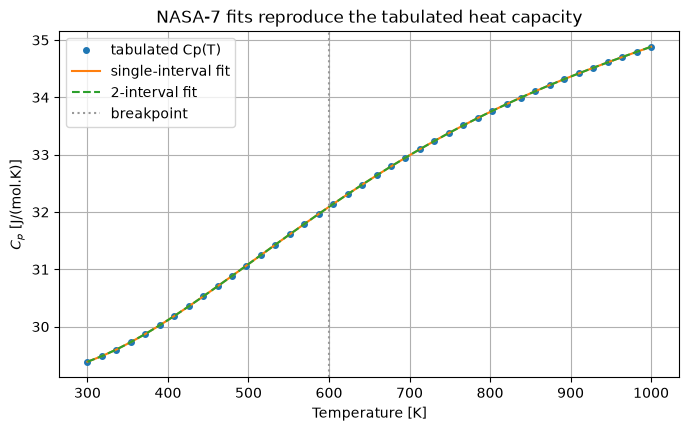

In [5]:
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True

fig, ax = plt.subplots()
ax.plot(T, cp_true, "o", ms=4, label="tabulated Cp(T)")
ax.plot(T, cp_fit, "-", label="single-interval fit")
ax.plot(T, cp_fit_multi, "--", label="2-interval fit")
ax.axvline(600.0, color="0.6", ls=":", label="breakpoint")
ax.set_xlabel("Temperature [K]")
ax.set_ylabel(r"$C_p$ [J/(mol.K)]")
ax.set_title("NASA-7 fits reproduce the tabulated heat capacity")
ax.legend()
plt.show()


## Resumen

- `fit_nasa7` recupera $a_1 \ldots a_7$ y ancla $b_1$ a $H^\circ(t_\mathrm{ref})$.
- `fit_nasa7_multi` divide el rango en puntos de quiebre con continuidad de $C_p$ y $C_p'$.
- Ambos usan la constante $R_\mathrm{GLENN}$ del conjunto de datos por defecto.
